#TASK 1 — DATA PREPARATION

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Display settings for better readability
pd.set_option('display.max_columns', None)

In [2]:
# ============================================
# STEP 1 — LOAD THE DATASET
# ============================================

# Why:
# Loading the dataset is the first step before
# performing any analysis or preprocessing.

# Upload the CSV file in Colab before running

df = pd.read_csv('/content/Telco_Customer_Churn_Dataset.csv')

# Display first 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# ============================================
# STEP 2 — UNDERSTAND THE DATASET
# ============================================

# Why:
# Before preprocessing, we must inspect:
# - Number of rows and columns
# - Data types
# - Missing values
# - Target variable structure

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe(include='all')

Dataset Shape:
(7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [4]:
# ============================================
# STEP 3 — CHECK TARGET VARIABLE
# ============================================

# Why:
# Understanding the target variable helps verify
# whether the problem is classification and
# ensures labels are clean.

print("Target Variable Distribution:\n")
print(df['Churn'].value_counts())

print("\nTarget Variable Percentage:\n")
print(df['Churn'].value_counts(normalize=True) * 100)

Target Variable Distribution:

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Target Variable Percentage:

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [5]:
# ============================================
# STEP 4 — HANDLE MISSING VALUES
# ============================================

# Why:
# Missing values can negatively impact model
# training and evaluation.

# Check missing values again
missing_values = df.isnull().sum()

print("Missing Values Before Cleaning:\n")
print(missing_values[missing_values > 0])

Missing Values Before Cleaning:

Series([], dtype: int64)


In [6]:
# ============================================
# STEP 5 — CLEAN TOTALCHARGES COLUMN
# ============================================

# Why:
# In Telco churn datasets, 'TotalCharges'
# often contains blank spaces instead of
# proper numeric values.

# Replace blank spaces with NaN
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)

# Convert to numeric datatype
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

# Fill missing values with median
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

print("Missing values after handling:")
print(df.isnull().sum().sum())

Missing values after handling:
0


/tmp/ipykernel_1942/4195533936.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [7]:
# ============================================
# STEP 6 — DROP IRRELEVANT COLUMNS
# ============================================

# Why:
# CustomerID is unique for every customer
# and does not help prediction.

if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
# ============================================
# STEP 7 — ENCODE CATEGORICAL VARIABLES
# ============================================

# Why:
# Machine learning models require numerical input.
# We convert categorical features into numbers.

# Store label encoders for future inverse transforms
label_encoders = {}

# Select categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Apply Label Encoding
for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

print("Categorical columns encoded successfully.")

Categorical columns encoded successfully.


In [10]:
# ============================================
# STEP 8 — DEFINE FEATURES AND TARGET
# ============================================

# Why:
# Separate independent variables (X)
# from the target variable (y).

X = df.drop('Churn', axis=1)
y = df['Churn']

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (7043, 20)
Target Shape: (7043,)


In [11]:
# ============================================
# STEP 9 — SPLIT DATASET (80/20)
# ============================================

# Why:
# Training data is used to train the model,
# while testing data evaluates performance
# on unseen data.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (5634, 20)
Testing Features Shape: (1409, 20)
Training Target Shape: (5634,)
Testing Target Shape: (1409,)


In [12]:
# ============================================
# STEP 10 — FINAL DATA VALIDATION
# ============================================

# Why:
# Final validation ensures the dataset is
# clean and ready for model training.

print("Any Missing Values Left?")
print(df.isnull().sum().sum())

print("\nEncoded Dataset Preview:")
df.head()

Any Missing Values Left?
0

Encoded Dataset Preview:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5375,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,2505,0
1,3962,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1466,0
2,2564,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,157,1
3,5535,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1400,0
4,6511,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,925,1


#Task 2 → Exploratory Data Analysis (EDA)

In [13]:
# ============================================
# TASK 2 — EXPLORATORY DATA ANALYSIS (EDA)
# ============================================

# Why:
# EDA helps us understand customer behavior,
# churn patterns, feature relationships,
# and important business insights.

import matplotlib.pyplot as plt
import seaborn as sns

# Better plot appearance
sns.set_style("whitegrid")

# Plot size defaults
plt.rcParams['figure.figsize'] = (8, 5)

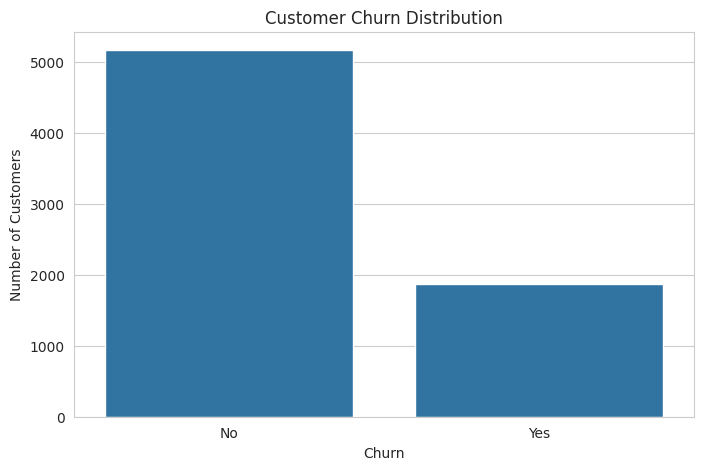

Churn Percentage:

No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [14]:
# ============================================
# STEP 1 — OVERALL CHURN RATE
# ============================================

# Why:
# Understanding churn distribution helps
# determine class imbalance and business risk.

# Convert encoded values back if needed
if df['Churn'].dtype != 'object':
    churn_labels = label_encoders['Churn'].inverse_transform(df['Churn'])
else:
    churn_labels = df['Churn']

# Plot churn distribution
sns.countplot(x=churn_labels)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

plt.show()

# Churn percentage
churn_rate = pd.Series(churn_labels).value_counts(normalize=True) * 100

print("Churn Percentage:\n")
print(churn_rate)

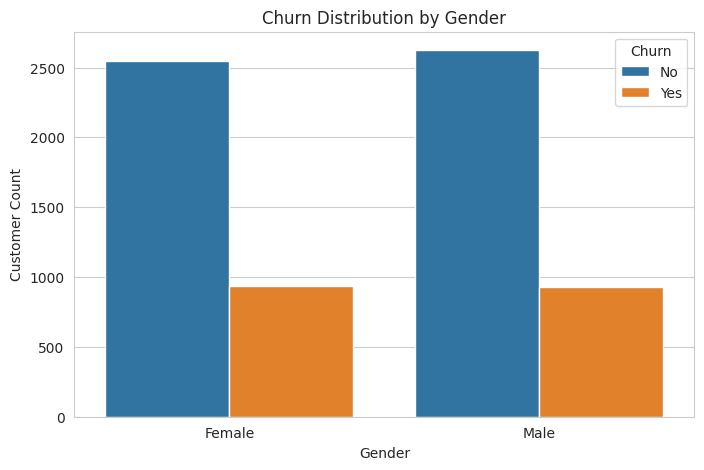

In [15]:
# ============================================
# STEP 2 — CHURN BY GENDER
# ============================================

# Why:
# Helps identify whether gender has any
# influence on customer churn behavior.

# Decode gender values
gender_labels = label_encoders['gender'].inverse_transform(df['gender'])

# Create temporary dataframe
temp_gender_df = pd.DataFrame({
    'Gender': gender_labels,
    'Churn': churn_labels
})

sns.countplot(data=temp_gender_df, x='Gender', hue='Churn')

plt.title('Churn Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Customer Count')

plt.show()

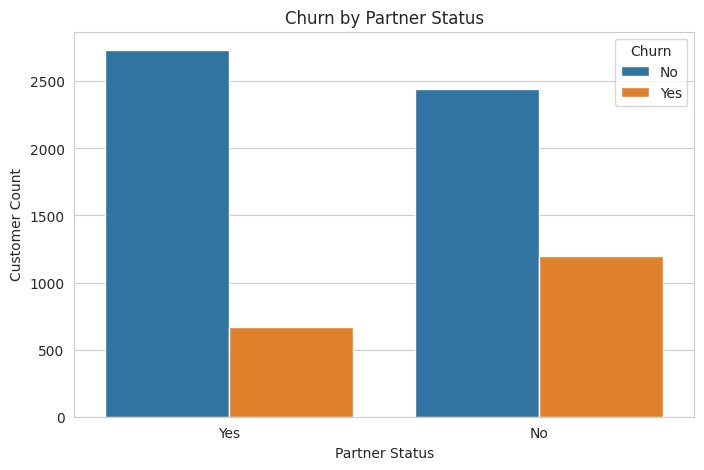

In [16]:
# ============================================
# STEP 3 — CHURN BY PARTNER STATUS
# ============================================

# Why:
# Customers with partners may show
# different retention behavior.

partner_labels = label_encoders['Partner'].inverse_transform(df['Partner'])

temp_partner_df = pd.DataFrame({
    'Partner': partner_labels,
    'Churn': churn_labels
})

sns.countplot(data=temp_partner_df, x='Partner', hue='Churn')

plt.title('Churn by Partner Status')
plt.xlabel('Partner Status')
plt.ylabel('Customer Count')

plt.show()

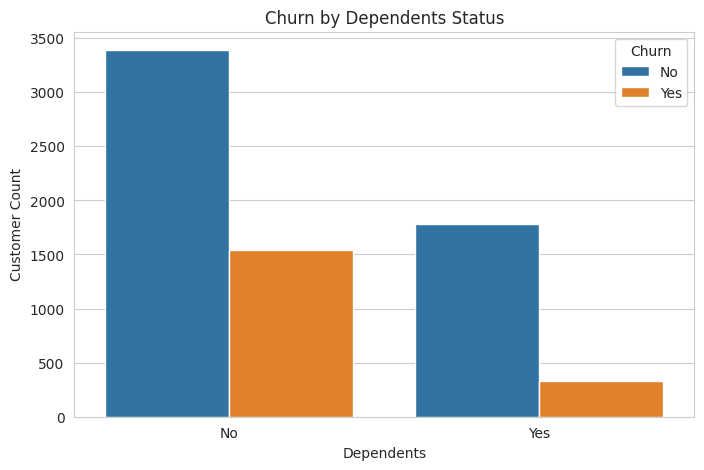

In [17]:
# ============================================
# STEP 4 — CHURN BY DEPENDENTS
# ============================================

# Why:
# Customers with dependents may have
# stronger long-term service usage.

dependent_labels = label_encoders['Dependents'].inverse_transform(df['Dependents'])

temp_dependents_df = pd.DataFrame({
    'Dependents': dependent_labels,
    'Churn': churn_labels
})

sns.countplot(data=temp_dependents_df, x='Dependents', hue='Churn')

plt.title('Churn by Dependents Status')
plt.xlabel('Dependents')
plt.ylabel('Customer Count')

plt.show()

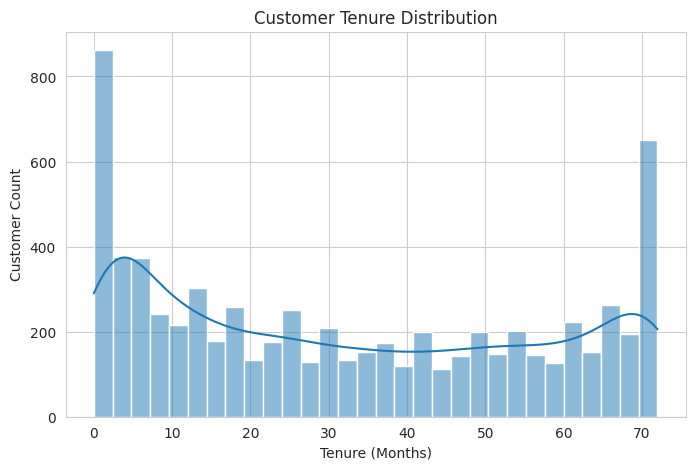

In [18]:
# ============================================
# STEP 5 — TENURE DISTRIBUTION
# ============================================

# Why:
# Tenure helps identify whether newer
# customers churn more frequently.

sns.histplot(data=df, x='tenure', bins=30, kde=True)

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Customer Count')

plt.show()

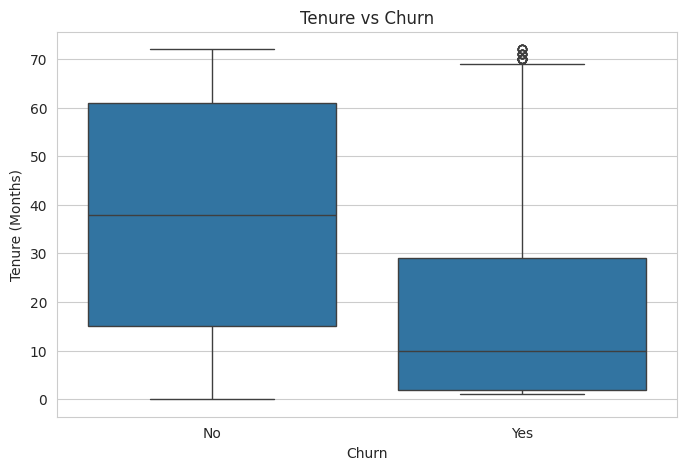

In [19]:
# ============================================
# STEP 6 — TENURE VS CHURN
# ============================================

# Why:
# Comparing tenure against churn reveals
# whether shorter-tenure customers are
# more likely to leave.

temp_tenure_df = df.copy()
temp_tenure_df['Churn'] = churn_labels

sns.boxplot(data=temp_tenure_df, x='Churn', y='tenure')

plt.title('Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

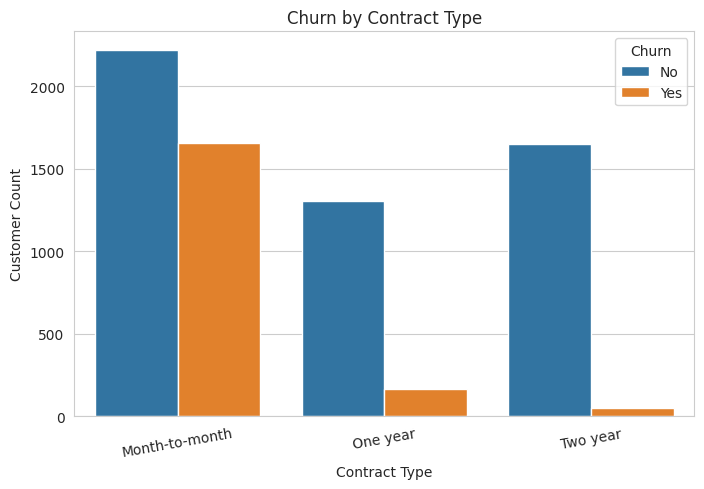

In [20]:
# ============================================
# STEP 7 — CONTRACT TYPE ANALYSIS
# ============================================

# Why:
# Contract type is usually one of the most
# important indicators of churn behavior.

contract_labels = label_encoders['Contract'].inverse_transform(df['Contract'])

temp_contract_df = pd.DataFrame({
    'Contract': contract_labels,
    'Churn': churn_labels
})

sns.countplot(
    data=temp_contract_df,
    x='Contract',
    hue='Churn'
)

plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')

plt.xticks(rotation=10)

plt.show()

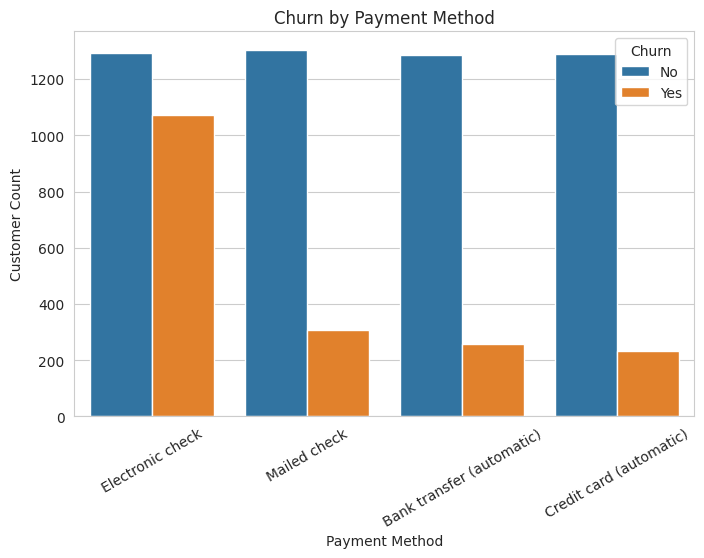

In [21]:
# ============================================
# STEP 8 — PAYMENT METHOD ANALYSIS
# ============================================

# Why:
# Certain payment methods may correlate
# with higher customer churn.

payment_labels = label_encoders['PaymentMethod'].inverse_transform(
    df['PaymentMethod']
)

temp_payment_df = pd.DataFrame({
    'PaymentMethod': payment_labels,
    'Churn': churn_labels
})

sns.countplot(
    data=temp_payment_df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Customer Count')

plt.xticks(rotation=30)

plt.show()

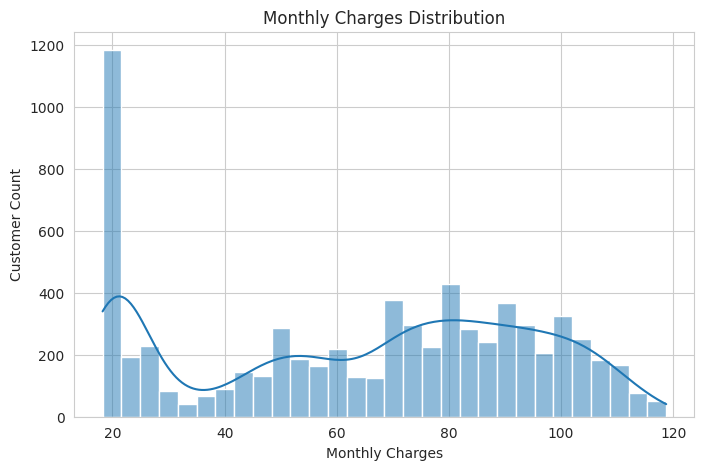

In [22]:
# ============================================
# STEP 9 — MONTHLY CHARGES DISTRIBUTION
# ============================================

# Why:
# Monthly charges may influence churn,
# especially for high-paying customers.

sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True)

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Customer Count')

plt.show()

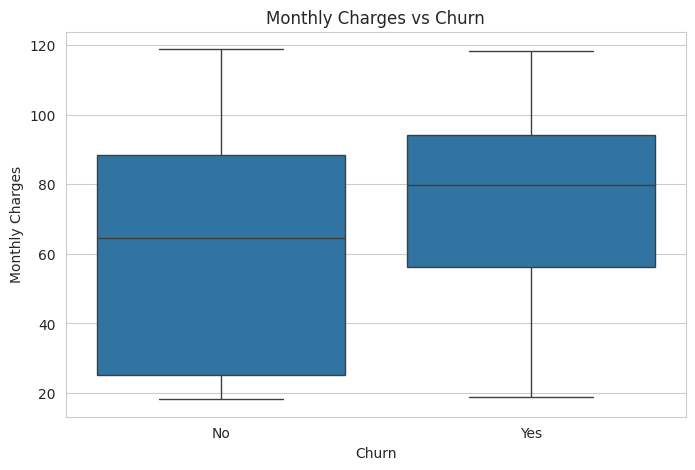

In [23]:
# ============================================
# STEP 10 — MONTHLY CHARGES VS CHURN
# ============================================

# Why:
# Helps determine whether customers paying
# higher monthly fees churn more often.

temp_monthly_df = df.copy()
temp_monthly_df['Churn'] = churn_labels

sns.boxplot(
    data=temp_monthly_df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

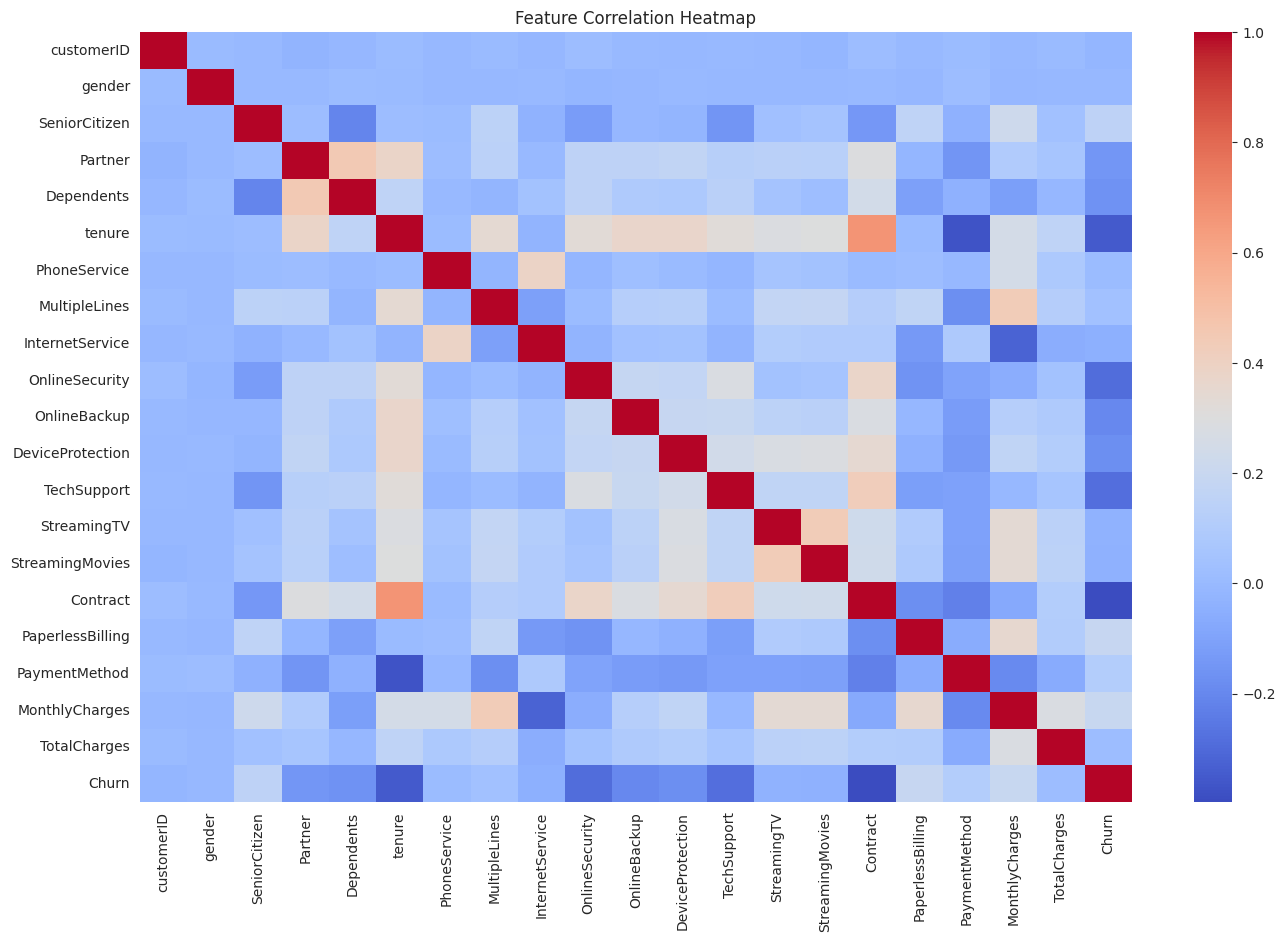

In [24]:
# ============================================
# STEP 11 — FEATURE CORRELATION HEATMAP
# ============================================

# Why:
# Correlation analysis helps identify
# important relationships between variables.

plt.figure(figsize=(16, 10))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    annot=False
)

plt.title('Feature Correlation Heatmap')

plt.show()

#Task 3: Customer Segmentation

In [25]:
# ============================================
# TASK 3 — CUSTOMER SEGMENTATION
# ============================================

# Why:
# Customer segmentation helps businesses:
# - Identify different customer groups
# - Understand churn behavior within segments
# - Target high-risk customers effectively

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [26]:
# ============================================
# STEP 1 — CREATE WORKING DATAFRAME
# ============================================

# Why:
# Creating a copy prevents accidental
# modification of the original dataset.

segmentation_df = df.copy()

# Decode churn values for readability
segmentation_df['Churn_Label'] = label_encoders['Churn'].inverse_transform(
    segmentation_df['Churn']
)

segmentation_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Label
0,5375,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,2505,0,No
1,3962,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1466,0,No
2,2564,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,157,1,Yes
3,5535,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1400,0,No
4,6511,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,925,1,Yes


In [27]:
# ============================================
# STEP 2 — TENURE-BASED SEGMENTATION
# ============================================

# Why:
# Segmenting customers by tenure helps
# identify whether newer customers are
# more likely to churn.

# Create tenure categories
segmentation_df['Tenure_Group'] = pd.cut(
    segmentation_df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=[
        '0-12 Months',
        '13-24 Months',
        '25-48 Months',
        '49-72 Months'
    ]
)

# Churn rate by tenure group
tenure_churn = (
    segmentation_df.groupby('Tenure_Group')['Churn']
    .mean() * 100
).round(2)

print("Churn Rate by Tenure Group (%):\n")
print(tenure_churn)

Churn Rate by Tenure Group (%):

Tenure_Group
0-12 Months     47.68
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: Churn, dtype: float64


/tmp/ipykernel_1942/2566349985.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segmentation_df.groupby('Tenure_Group')['Churn']


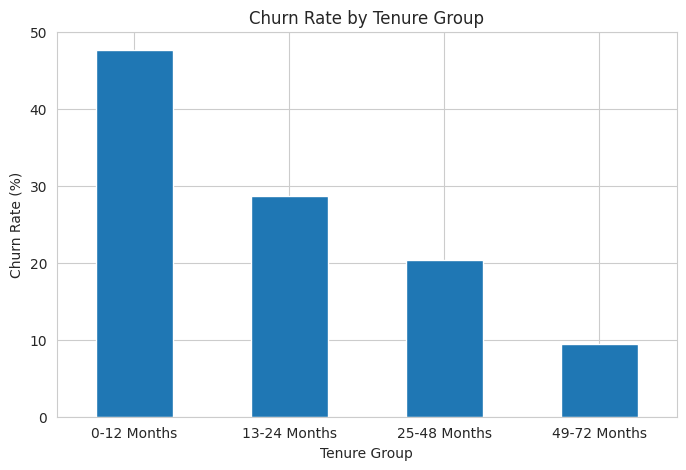

In [28]:
# ============================================
# STEP 3 — VISUALIZE TENURE SEGMENTS
# ============================================

# Why:
# Visualization makes it easier to identify
# high-risk customer groups.

tenure_churn.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Churn Rate by Tenure Group')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)

plt.show()

In [29]:
# ============================================
# STEP 4 — MONTHLY CHARGES SEGMENTATION
# ============================================

# Why:
# High-paying customers are important
# for revenue retention strategies.

# Create monthly charge groups
segmentation_df['MonthlyCharge_Group'] = pd.qcut(
    segmentation_df['MonthlyCharges'],
    q=4,
    labels=[
        'Low Charges',
        'Medium Charges',
        'High Charges',
        'Premium Charges'
    ]
)

# Calculate churn rate
monthly_charge_churn = (
    segmentation_df.groupby('MonthlyCharge_Group')['Churn']
    .mean() * 100
).round(2)

print("Churn Rate by Monthly Charge Segment (%):\n")
print(monthly_charge_churn)

Churn Rate by Monthly Charge Segment (%):

MonthlyCharge_Group
Low Charges        11.24
Medium Charges     24.58
High Charges       37.51
Premium Charges    32.88
Name: Churn, dtype: float64


/tmp/ipykernel_1942/535033317.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segmentation_df.groupby('MonthlyCharge_Group')['Churn']


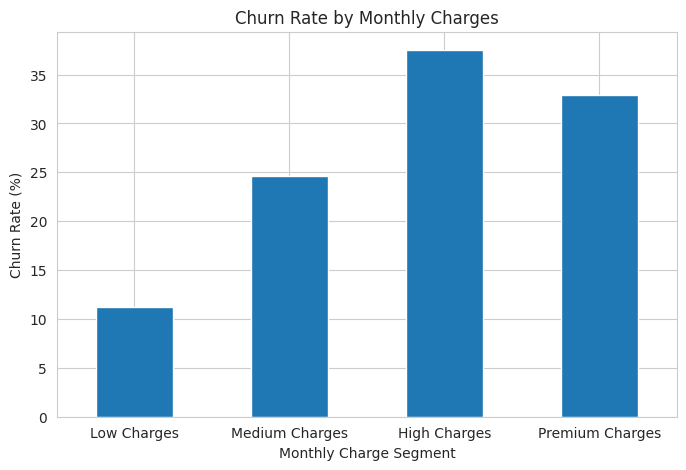

In [30]:
# ============================================
# STEP 5 — VISUALIZE MONTHLY CHARGE SEGMENTS
# ============================================

monthly_charge_churn.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Churn Rate by Monthly Charges')
plt.xlabel('Monthly Charge Segment')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=0)

plt.show()

In [31]:
# ============================================
# STEP 6 — CONTRACT TYPE SEGMENTATION
# ============================================

# Why:
# Contract type is one of the strongest
# indicators of customer loyalty.

# Decode contract labels
segmentation_df['Contract_Label'] = label_encoders['Contract'].inverse_transform(
    segmentation_df['Contract']
)

# Churn by contract type
contract_churn = (
    segmentation_df.groupby('Contract_Label')['Churn']
    .mean() * 100
).round(2)

print("Churn Rate by Contract Type (%):\n")
print(contract_churn)

Churn Rate by Contract Type (%):

Contract_Label
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


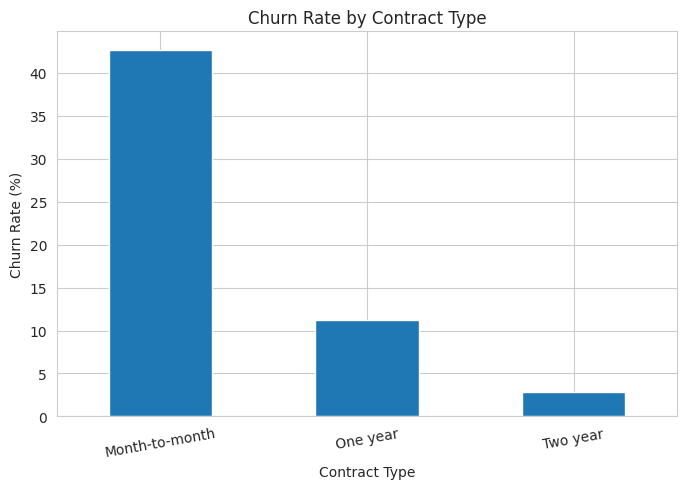

In [32]:
# ============================================
# STEP 7 — VISUALIZE CONTRACT SEGMENTS
# ============================================

contract_churn.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.xticks(rotation=10)

plt.show()

In [33]:
# ============================================
# STEP 8 — IDENTIFY HIGH-VALUE CUSTOMERS
# ============================================

# Why:
# High-value customers contribute more
# revenue and should receive retention focus.

# Define high-value customers
# Criteria:
# - High monthly charges
# - Long tenure
# - Month-to-month contract

high_value_customers = segmentation_df[
    (segmentation_df['MonthlyCharges'] >= segmentation_df['MonthlyCharges'].quantile(0.75)) &
    (segmentation_df['tenure'] >= 24)
]

print("Number of High-Value Customers:")
print(high_value_customers.shape[0])

high_value_customers.head()

Number of High-Value Customers:
1372


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Label,Tenure_Group,MonthlyCharge_Group,Contract_Label
8,5604,0,0,1,0,28,1,2,1,0,0,2,2,2,2,0,1,2,104.80,2646,1,Yes,25-48 Months,Premium Charges,Month-to-month
12,5751,1,0,1,0,58,1,2,1,0,0,2,0,2,2,1,0,1,100.35,4693,0,No,49-72 Months,Premium Charges,One year
13,174,1,0,0,0,49,1,2,1,0,2,2,0,2,2,0,1,0,103.70,4265,1,Yes,49-72 Months,Premium Charges,Month-to-month
14,3615,1,0,0,0,25,1,0,1,2,0,2,2,2,2,0,1,2,105.50,2337,0,No,25-48 Months,Premium Charges,Month-to-month
15,2556,0,0,1,1,69,1,2,1,2,2,2,2,2,2,2,0,1,113.25,5959,0,No,49-72 Months,Premium Charges,Two year


In [34]:
# ============================================
# STEP 9 — IDENTIFY HIGH-RISK CUSTOMERS
# ============================================

# Why:
# High-risk customers are customers likely
# to churn and require immediate action.

# High-risk criteria
high_risk_customers = segmentation_df[
    (segmentation_df['Tenure_Group'] == '0-12 Months') &
    (segmentation_df['MonthlyCharge_Group'].isin(['High Charges', 'Premium Charges']))
]

print("Number of High-Risk Customers:")
print(high_risk_customers.shape[0])

high_risk_customers.head()

Number of High-Risk Customers:
828


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Label,Tenure_Group,MonthlyCharge_Group,Contract_Label
4,6511,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,925,1,Yes,0-12 Months,High Charges,Month-to-month
5,6551,0,0,0,0,8,1,2,1,0,0,2,0,2,2,0,1,2,99.65,6104,1,Yes,0-12 Months,Premium Charges,Month-to-month
31,3481,1,1,1,0,2,1,0,1,0,0,2,0,2,2,0,1,1,95.50,1360,0,No,0-12 Months,Premium Charges,Month-to-month
39,5803,0,0,0,0,11,1,2,1,0,0,2,0,2,2,0,1,0,97.85,202,1,Yes,0-12 Months,Premium Charges,Month-to-month
47,5510,0,0,0,0,2,1,0,1,0,0,0,0,2,0,0,1,2,80.65,809,1,Yes,0-12 Months,High Charges,Month-to-month


In [35]:
# ============================================
# STEP 10 — SEGMENT SUMMARY TABLE
# ============================================

# Why:
# A summary table provides a consolidated
# business overview for reporting.

segment_summary = segmentation_df.groupby(
    ['Tenure_Group', 'MonthlyCharge_Group']
).agg(
    Total_Customers=('Churn', 'count'),
    Churn_Rate=('Churn', 'mean'),
    Avg_Monthly_Charges=('MonthlyCharges', 'mean')
).reset_index()

# Convert churn rate to percentage
segment_summary['Churn_Rate'] = (
    segment_summary['Churn_Rate'] * 100
).round(2)

segment_summary.head(10)

/tmp/ipykernel_1942/676743674.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segment_summary = segmentation_df.groupby(


,Tenure_Group,MonthlyCharge_Group,Total_Customers,Churn_Rate,Avg_Monthly_Charges
0,0-12 Months,Low Charges,646,24.61,22.174149
1,0-12 Months,Medium Charges,701,43.79,54.877318
2,0-12 Months,High Charges,608,66.45,79.168914
3,0-12 Months,Premium Charges,220,75.91,96.572500
4,13-24 Months,Low Charges,276,5.80,22.020652
5,13-24 Months,Medium Charges,276,22.10,55.793841
6,13-24 Months,High Charges,278,40.29,80.864388
7,13-24 Months,Premium Charges,194,54.12,97.282216
8,25-48 Months,Low Charges,383,4.44,22.320757
9,25-48 Months,Medium Charges,380,11.05,55.572500


/tmp/ipykernel_1942/2229647797.py:9: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = segmentation_df.pivot_table(


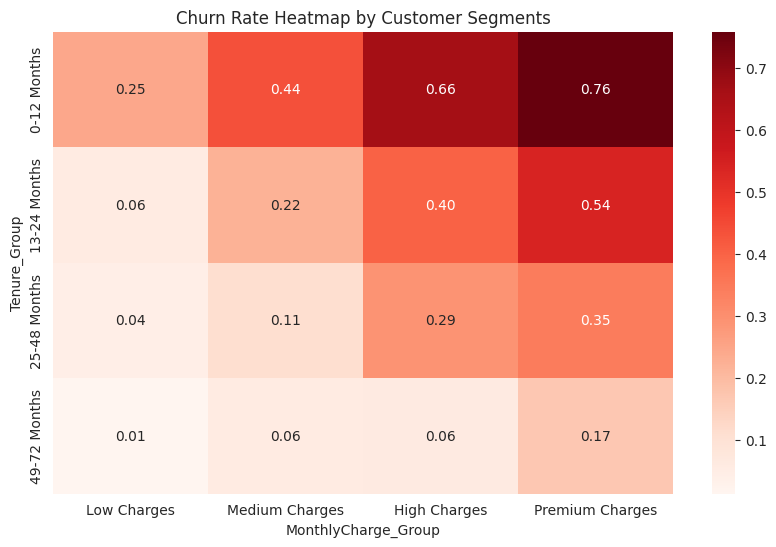

In [36]:
# ============================================
# STEP 11 — SEGMENTATION HEATMAP
# ============================================

# Why:
# Heatmaps help identify combinations
# of customer groups with high churn risk.

heatmap_data = segmentation_df.pivot_table(
    values='Churn',
    index='Tenure_Group',
    columns='MonthlyCharge_Group',
    aggfunc='mean'
)

plt.figure(figsize=(10,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap='Reds',
    fmt='.2f'
)

plt.title('Churn Rate Heatmap by Customer Segments')

plt.show()

#Task 4: Churn Prediction Model

In [37]:
# ============================================
# TASK 4 — CHURN PREDICTION MODELS
# ============================================

# Why:
# In this task, we build machine learning
# models to predict customer churn.

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
# ============================================
# STEP 1 — VERIFY TRAINING DATA
# ============================================

# Why:
# Before training models, verify dataset
# dimensions and class distribution.

print("Training Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

Training Feature Shape: (5634, 20)
Testing Feature Shape: (1409, 20)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64


In [39]:
# ============================================
# STEP 2 — TRAIN LOGISTIC REGRESSION MODEL
# ============================================

# Why:
# Logistic Regression is a strong baseline
# model for binary classification problems.

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [40]:
# ============================================
# STEP 3 — PREDICTIONS USING LOGISTIC MODEL
# ============================================

# Why:
# Predictions help evaluate model performance
# on unseen testing data.

y_pred_logistic = logistic_model.predict(X_test)

In [41]:
# ============================================
# STEP 4 — EVALUATE LOGISTIC REGRESSION
# ============================================

# Why:
# Evaluation metrics help measure:
# - Accuracy
# - Precision
# - Recall
# - F1-score

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)

print("===== Logistic Regression Performance =====\n")

print(f"Accuracy  : {logistic_accuracy:.4f}")
print(f"Precision : {logistic_precision:.4f}")
print(f"Recall    : {logistic_recall:.4f}")
print(f"F1-Score  : {logistic_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_logistic))

===== Logistic Regression Performance =====

Accuracy  : 0.7921
Precision : 0.6302
Recall    : 0.5241
F1-Score  : 0.5723

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1035
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



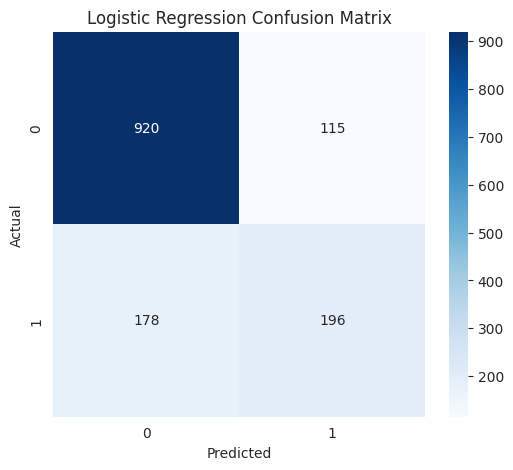

In [42]:
# ============================================
# STEP 5 — CONFUSION MATRIX (LOGISTIC)
# ============================================

# Why:
# Confusion matrix shows:
# - Correct predictions
# - False positives
# - False negatives

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [43]:
# ============================================
# STEP 6 — TRAIN RANDOM FOREST MODEL
# ============================================

# Why:
# Random Forest handles:
# - Non-linear relationships
# - Feature interactions
# - Complex patterns

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

# Train model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully")

Random Forest Model Trained Successfully


In [44]:
# ============================================
# STEP 7 — RANDOM FOREST PREDICTIONS
# ============================================

y_pred_rf = rf_model.predict(X_test)

In [45]:
# ============================================
# STEP 8 — EVALUATE RANDOM FOREST MODEL
# ============================================

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

print("===== Random Forest Performance =====\n")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))

===== Random Forest Performance =====

Accuracy  : 0.8020
Precision : 0.6678
Recall    : 0.5053
F1-Score  : 0.5753

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



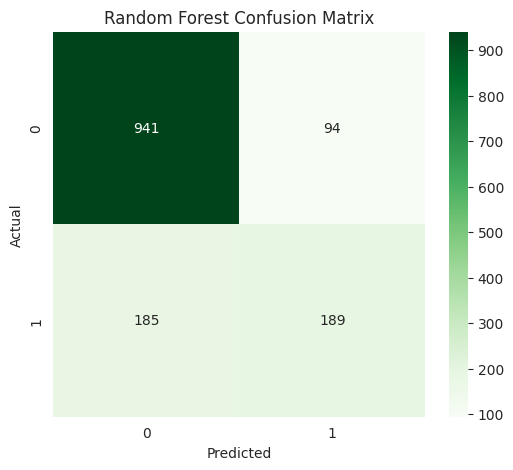

In [46]:
# ============================================
# STEP 9 — CONFUSION MATRIX (RANDOM FOREST)
# ============================================

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [47]:
# ============================================
# STEP 10 — MODEL COMPARISON TABLE
# ============================================

# Why:
# Comparing models helps identify
# the best-performing algorithm.

model_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [logistic_accuracy, rf_accuracy],
    'Precision': [logistic_precision, rf_precision],
    'Recall': [logistic_recall, rf_recall],
    'F1-Score': [logistic_f1, rf_f1]
})

model_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.792051,0.630225,0.524064,0.572263
1,Random Forest,0.801987,0.667845,0.505348,0.575342


In [48]:
# ============================================
# STEP 11 — IDENTIFY BEST MODEL
# ============================================

# Why:
# F1-score balances precision and recall,
# making it ideal for churn prediction.

best_model = model_results.sort_values(
    by='F1-Score',
    ascending=False
).iloc[0]

print("Best Performing Model:\n")
print(best_model)

Best Performing Model:

Model        Random Forest
Accuracy          0.801987
Precision         0.667845
Recall            0.505348
F1-Score          0.575342
Name: 1, dtype: object


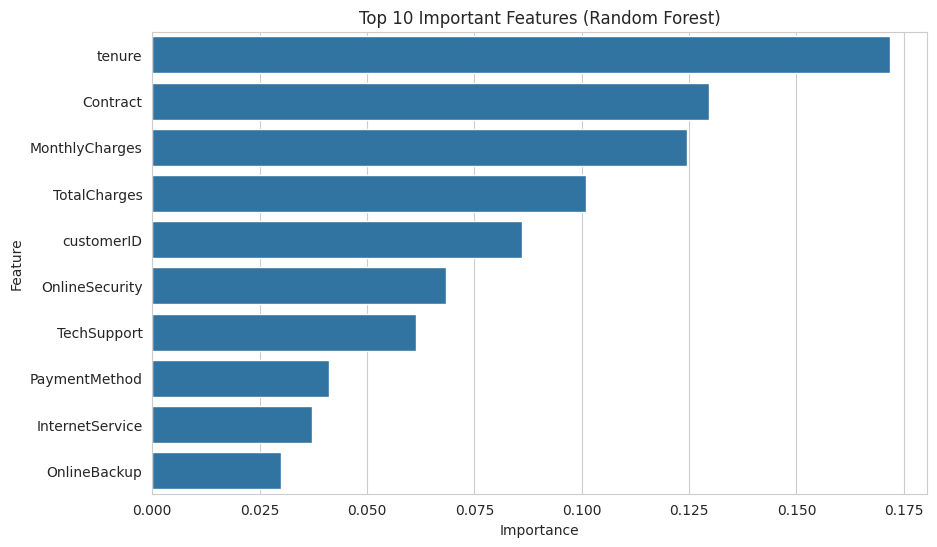

,Feature,Importance
5,tenure,0.171879
15,Contract,0.129697
18,MonthlyCharges,0.124418
19,TotalCharges,0.101104
0,customerID,0.086028
9,OnlineSecurity,0.068468
12,TechSupport,0.061493
17,PaymentMethod,0.041194
8,InternetService,0.037253
10,OnlineBackup,0.029893


In [49]:
# ============================================
# STEP 12 — FEATURE IMPORTANCE
# ============================================

# Why:
# Feature importance helps understand
# which variables influence churn most.

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Top 10 important features
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features (Random Forest)')

plt.show()

top_features

#Task 5: Model Evaluation and Interpretation

In [50]:
# ============================================
# TASK 5 — MODEL EVALUATION & INTERPRETATION
# ============================================

# Why:
# This task evaluates the best-performing model
# using ROC Curve and AUC score while also
# interpreting feature importance.

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
# ============================================
# STEP 1 — SELECT BEST MODEL
# ============================================

# Why:
# We use the model with the highest F1-score
# for advanced evaluation.

if rf_f1 >= logistic_f1:
    best_model_name = "Random Forest"
    best_model = rf_model
    y_pred_best = y_pred_rf
else:
    best_model_name = "Logistic Regression"
    best_model = logistic_model
    y_pred_best = y_pred_logistic

print(f"Best Model Selected: {best_model_name}")

Best Model Selected: Random Forest


In [52]:
# ============================================
# STEP 2 — PREDICT PROBABILITIES
# ============================================

# Why:
# ROC curves require probability scores
# rather than class labels.

y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("Probability predictions generated successfully.")

Probability predictions generated successfully.


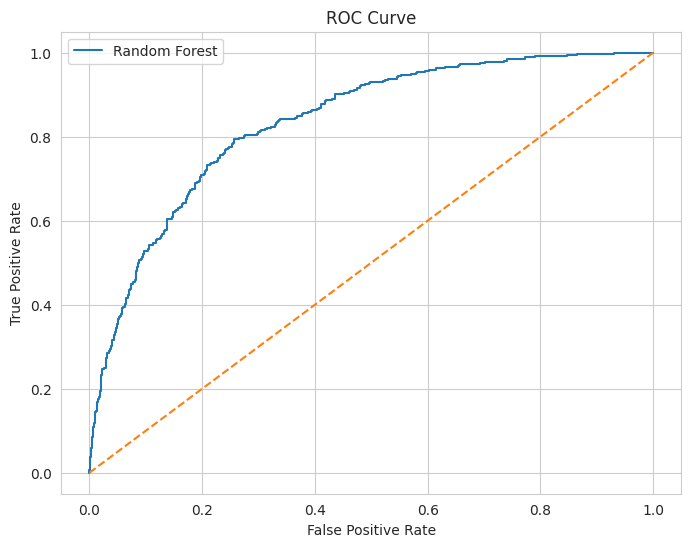

In [53]:
# ============================================
# STEP 3 — GENERATE ROC CURVE
# ============================================

# Why:
# ROC Curve evaluates how well the model
# distinguishes churn vs non-churn customers.

fpr, tpr, thresholds = roc_curve(y_test, y_prob_best)

plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f'{best_model_name}')

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()

plt.show()

In [54]:
# ============================================
# STEP 4 — CALCULATE AUC SCORE
# ============================================

# Why:
# AUC measures the model's ability
# to separate churners from non-churners.

auc_score = roc_auc_score(y_test, y_prob_best)

print(f"AUC Score for {best_model_name}: {auc_score:.4f}")

AUC Score for Random Forest: 0.8346


In [55]:
# ============================================
# STEP 5 — INTERPRET AUC SCORE
# ============================================

# Why:
# Business interpretation helps explain
# model quality in simple terms.

if auc_score >= 0.90:
    interpretation = "Excellent Model Performance"
elif auc_score >= 0.80:
    interpretation = "Very Good Model Performance"
elif auc_score >= 0.70:
    interpretation = "Good Model Performance"
elif auc_score >= 0.60:
    interpretation = "Average Model Performance"
else:
    interpretation = "Poor Model Performance"

print("Model Interpretation:")
print(interpretation)

Model Interpretation:
Very Good Model Performance


In [56]:
# ============================================
# STEP 6 — FEATURE IMPORTANCE ANALYSIS
# ============================================

# Why:
# Identifying influential features helps
# businesses understand churn drivers.

if best_model_name == "Random Forest":

    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_model.feature_importances_
    })

    feature_importance = feature_importance.sort_values(
        by='Importance',
        ascending=False
    )

    print("Top Important Features:\n")
    print(feature_importance.head(10))

else:

    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Coefficient': logistic_model.coef_[0]
    })

    feature_importance['Absolute_Coefficient'] = (
        feature_importance['Coefficient'].abs()
    )

    feature_importance = feature_importance.sort_values(
        by='Absolute_Coefficient',
        ascending=False
    )

    print("Top Influential Features:\n")
    print(feature_importance.head(10))

Top Important Features:

            Feature  Importance
5            tenure    0.171879
15         Contract    0.129697
18   MonthlyCharges    0.124418
19     TotalCharges    0.101104
0        customerID    0.086028
9    OnlineSecurity    0.068468
12      TechSupport    0.061493
17    PaymentMethod    0.041194
8   InternetService    0.037253
10     OnlineBackup    0.029893


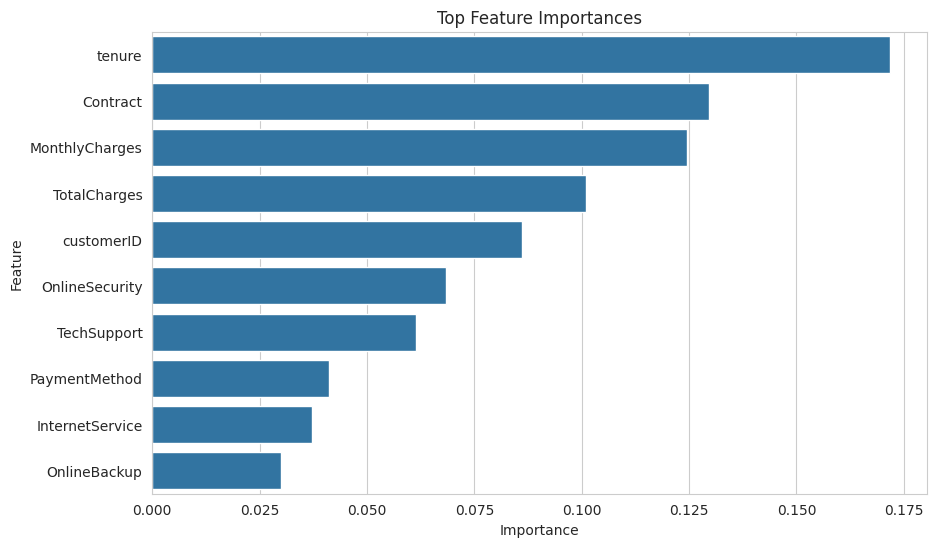

In [57]:
# ============================================
# STEP 7 — VISUALIZE FEATURE IMPORTANCE
# ============================================

# Why:
# Visualization improves interpretability
# for reports and presentations.

plt.figure(figsize=(10,6))

if best_model_name == "Random Forest":

    top_features = feature_importance.head(10)

    sns.barplot(
        data=top_features,
        x='Importance',
        y='Feature'
    )

    plt.title('Top Feature Importances')

else:

    top_features = feature_importance.head(10)

    sns.barplot(
        data=top_features,
        x='Absolute_Coefficient',
        y='Feature'
    )

    plt.title('Top Logistic Regression Coefficients')

plt.show()

In [58]:
# ============================================
# STEP 8 — FINAL MODEL SUMMARY
# ============================================

# Why:
# A concise summary helps present findings
# clearly in internship reports.

print("========== FINAL MODEL SUMMARY ==========\n")

print(f"Best Model        : {best_model_name}")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision         : {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall            : {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score          : {f1_score(y_test, y_pred_best):.4f}")
print(f"AUC Score         : {auc_score:.4f}")

print("\nOverall Interpretation:")
print(interpretation)

========== FINAL MODEL SUMMARY ==========

Best Model        : Random Forest
Accuracy          : 0.8020
Precision         : 0.6678
Recall            : 0.5053
F1-Score          : 0.5753
AUC Score         : 0.8346

Overall Interpretation:
Very Good Model Performance


#Task 6: Business Recommendations

In [59]:
# ============================================
# TASK 6 — BUSINESS RECOMMENDATIONS
# ============================================

# Why:
# The final task converts analytical findings
# into actionable business strategies that can:
# - Reduce churn
# - Improve retention
# - Increase customer lifetime value
# - Protect recurring revenue

In [60]:
# ============================================
# STEP 1 — IDENTIFY HIGH-RISK CUSTOMERS
# ============================================

# Why:
# Customers with high churn probability
# should receive immediate retention actions.

# Generate churn probabilities
churn_probabilities = best_model.predict_proba(X_test)[:, 1]

# Create results dataframe
results_df = X_test.copy()

results_df['Actual_Churn'] = y_test.values
results_df['Predicted_Churn_Probability'] = churn_probabilities

# Sort highest-risk customers
high_risk_customers = results_df.sort_values(
    by='Predicted_Churn_Probability',
    ascending=False
)

# Top 10 high-risk customers
high_risk_customers.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn_Probability
3380,3672,1,1,1,0,1,1,2,1,0,0,0,0,2,2,0,1,2,95.10,6442,1,0.886306
4585,725,0,1,0,0,1,1,2,1,0,0,0,0,0,2,0,1,2,85.05,6207,1,0.876573
2927,3938,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,2,69.90,5454,0,0.872007
6866,180,1,0,0,0,1,1,2,1,0,0,0,0,2,2,0,1,2,95.45,6443,1,0.868703
6623,6516,1,1,0,0,1,1,2,1,0,0,0,0,0,0,0,1,2,76.45,5824,1,0.865565
809,1230,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,2,69.55,5447,1,0.864026
3682,2601,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,2,69.10,5440,1,0.857120
1731,5939,0,1,0,0,1,1,0,1,0,0,0,0,0,0,0,1,2,69.60,5448,1,0.856277
6633,3080,0,0,0,0,1,1,2,1,0,0,0,0,0,0,0,1,2,74.50,5721,1,0.850015
642,663,1,0,0,0,1,1,0,1,0,0,0,0,2,2,0,1,2,89.55,6302,1,0.847124


In [61]:
# ============================================
# STEP 2 — CREATE RISK SEGMENTS
# ============================================

# Why:
# Segmenting customers by churn probability
# helps prioritize retention campaigns.

def assign_risk(probability):

    if probability >= 0.75:
        return 'High Risk'

    elif probability >= 0.50:
        return 'Medium Risk'

    else:
        return 'Low Risk'

# Apply segmentation
high_risk_customers['Risk_Level'] = (
    high_risk_customers['Predicted_Churn_Probability']
    .apply(assign_risk)
)

# Count customers by risk
risk_summary = high_risk_customers['Risk_Level'].value_counts()

print(risk_summary)

Risk_Level
Low Risk       1126
Medium Risk     221
High Risk        62
Name: count, dtype: int64


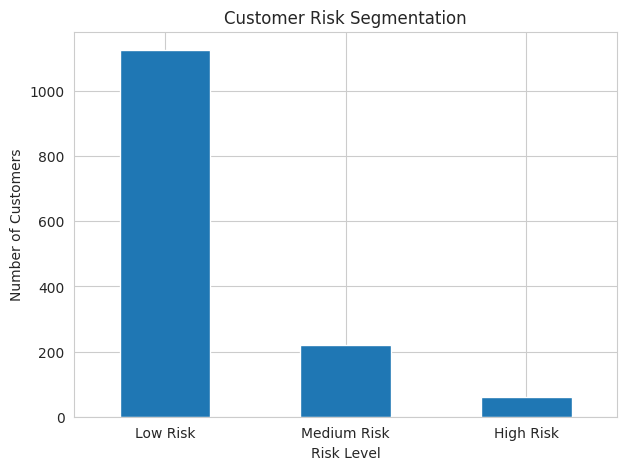

In [62]:
# ============================================
# STEP 3 — VISUALIZE CUSTOMER RISK LEVELS
# ============================================

# Why:
# Visualization helps management understand
# churn exposure across customer groups.

risk_summary.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Customer Risk Segmentation')
plt.xlabel('Risk Level')
plt.ylabel('Number of Customers')

plt.xticks(rotation=0)

plt.show()

In [63]:
# ============================================
# STEP 4 — RETENTION STRATEGY MAPPING
# ============================================

# Why:
# Different customer segments require
# different retention approaches.

def retention_strategy(risk):

    if risk == 'High Risk':
        return 'Immediate retention offer + personal engagement'

    elif risk == 'Medium Risk':
        return 'Discounts and loyalty rewards'

    else:
        return 'Regular engagement campaigns'

# Assign strategies
high_risk_customers['Recommended_Action'] = (
    high_risk_customers['Risk_Level']
    .apply(retention_strategy)
)

# Preview recommendations
high_risk_customers[
    ['Predicted_Churn_Probability',
     'Risk_Level',
     'Recommended_Action']
].head(10)

,Predicted_Churn_Probability,Risk_Level,Recommended_Action
3380,0.886306,High Risk,Immediate retention offer + personal engagement
4585,0.876573,High Risk,Immediate retention offer + personal engagement
2927,0.872007,High Risk,Immediate retention offer + personal engagement
6866,0.868703,High Risk,Immediate retention offer + personal engagement
6623,0.865565,High Risk,Immediate retention offer + personal engagement
809,0.864026,High Risk,Immediate retention offer + personal engagement
3682,0.857120,High Risk,Immediate retention offer + personal engagement
1731,0.856277,High Risk,Immediate retention offer + personal engagement
6633,0.850015,High Risk,Immediate retention offer + personal engagement
642,0.847124,High Risk,Immediate retention offer + personal engagement


In [64]:
# ============================================
# STEP 5 — ESTIMATE REVENUE AT RISK
# ============================================

# Why:
# Estimating revenue impact helps justify
# retention investment decisions.

if 'MonthlyCharges' in high_risk_customers.columns:

    # Estimate monthly revenue risk
    revenue_at_risk = (
        high_risk_customers[
            high_risk_customers['Risk_Level'] == 'High Risk'
        ]['MonthlyCharges'].sum()
    )

    print(f"Estimated Monthly Revenue at Risk: ${revenue_at_risk:.2f}")

else:
    print("MonthlyCharges column not available.")

Estimated Monthly Revenue at Risk: $5195.35


In [65]:
# ============================================
# STEP 6 — BUSINESS RECOMMENDATION SUMMARY
# ============================================

# Why:
# Final recommendations provide actionable
# strategies for business stakeholders.

recommendations = [
    "Provide long-term contract incentives for month-to-month customers.",
    "Offer personalized discounts to high-risk customers.",
    "Improve onboarding experience for new customers.",
    "Introduce loyalty rewards for premium customers.",
    "Develop proactive customer support programs.",
    "Use churn prediction models for early intervention campaigns."
]

print("========== BUSINESS RECOMMENDATIONS ==========\n")

for i, recommendation in enumerate(recommendations, start=1):
    print(f"{i}. {recommendation}")

========== BUSINESS RECOMMENDATIONS ==========

1. Provide long-term contract incentives for month-to-month customers.
2. Offer personalized discounts to high-risk customers.
3. Improve onboarding experience for new customers.
4. Introduce loyalty rewards for premium customers.
5. Develop proactive customer support programs.
6. Use churn prediction models for early intervention campaigns.


In [66]:
# ============================================
# STEP 7 — ESTIMATE POTENTIAL BUSINESS IMPACT
# ============================================

# Why:
# Estimating impact demonstrates the value
# of predictive analytics to management.

# Example assumptions
estimated_churn_reduction = 10  # %
estimated_revenue_protection = revenue_at_risk * 0.10

print("========== ESTIMATED BUSINESS IMPACT ==========\n")

print(f"Potential Churn Reduction      : {estimated_churn_reduction}%")
print(f"Estimated Revenue Protection   : ${estimated_revenue_protection:.2f}")

========== ESTIMATED BUSINESS IMPACT ==========

Potential Churn Reduction      : 10%
Estimated Revenue Protection   : $519.54


In [67]:
# ============================================
# STEP 8 — FINAL PROJECT CONCLUSION
# ============================================

# Why:
# A concise conclusion improves report quality
# and presentation clarity.

print("""
================ FINAL CONCLUSION ================

The churn prediction system successfully identified
customers at high risk of leaving the company.

Key findings:
- Short-tenure customers show higher churn behavior.
- Month-to-month contracts have the highest churn rate.
- Customers with higher monthly charges are more vulnerable.

The Random Forest model achieved the best overall
performance and effectively identified churn patterns.

Business Impact:
- Early identification of high-risk customers
  enables proactive retention strategies.
- Personalized engagement campaigns can reduce churn.
- Revenue loss can be minimized using predictive analytics.

==================================================
""")


================ FINAL CONCLUSION ================

The churn prediction system successfully identified
customers at high risk of leaving the company.

Key findings:
- Short-tenure customers show higher churn behavior.
- Month-to-month contracts have the highest churn rate.
- Customers with higher monthly charges are more vulnerable.

The Random Forest model achieved the best overall
performance and effectively identified churn patterns.

Business Impact:
- Early identification of high-risk customers
  enables proactive retention strategies.
- Personalized engagement campaigns can reduce churn.
- Revenue loss can be minimized using predictive analytics.


